# Afterglow dataloader (piloto)

Población continua de afterglows de GRB con `afterglowpy` (Ryan et al. 2020), sin clases short/long y sin priors de forma: cada parámetro se sortea uniforme o log-uniforme entre dos límites.

- **Parámetros físicos** (energía, densidad, $p$, $\epsilon_e$, $\epsilon_B$): mínimo y máximo exactos de Fong et al. (2015, Tabla 3) y Aksulu et al. (2022, Tablas 5 y 6).
- **Geometría** (ángulo del core y de visión): criterio propio, todo lo que acepta `afterglowpy`, con el ángulo de visión isotrópico.
- **Polvo del host**: $A_V$ exponencial con mediana 0.15 mag (22 lGRB de Aksulu et al. 2022); una fracción 0.096 (fracción de sGRB en Swift/BAT, Lien et al. 2016) va con $A_V = 0$. Curva SMC (Gordon et al. 2003) en reposo.

Los límites viven en `configs/afterglow.yaml` y el código en `kilonova.simulation.afterglow_contaminants`.

**Parte 1** muestra los afterglows tal como salen de `afterglowpy`. **Parte 2** los pasa por Roman: bandpasses, cadencia de 5 d, receta de ruido y ventana desde la primera detección, igual que las kilonovas.

In [1]:
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

from kilonova.photometry.roman_noise import (
    BASE_CADENCE_DAYS,
    build_tier_constants,
    flux_error_electrons,
    limiting_magnitude_5sigma,
)
from kilonova.photometry.spectra import ALL_ROMAN_BANDS
from kilonova.simulation import afterglow_contaminants
from kilonova.simulation.early_windows import N_KN_VISITS

NUMBER_OF_AFTERGLOWS = 2000
POPULATION_SEED = 0
TIERS = ['deep', 'wide']
TIER_COLOR = {'deep': 'tab:red', 'wide': 'tab:blue'}
REFERENCE_BAND = 'J129'
REFERENCE_WAVELENGTH_AA = 12900.0
BAND_WAVELENGTH_MICRON = {'R062': 0.62, 'Z087': 0.87, 'Y106': 1.06, 'J129': 1.29, 'H158': 1.58, 'F184': 1.84}
BAND_COLOR = {}
for band, wavelength in BAND_WAVELENGTH_MICRON.items():
    BAND_COLOR[band] = plt.cm.turbo((wavelength - 0.55) / 1.7)

CONFIG = afterglow_contaminants.load_afterglow_config()
TIER_CONSTANTS = {}
for tier in TIERS:
    TIER_CONSTANTS[tier] = build_tier_constants(tier)


def limiting_magnitude(tier, band):
    constants = TIER_CONSTANTS[tier]
    background_error = flux_error_electrons(0.0, constants['noise_floor_variance'][band])
    return limiting_magnitude_5sigma(background_error, constants['exposure_time'][band], constants['zeropoint'][band])


def viewing_over_core(population):
    return population['viewing_angle_rad'] / population['core_angle_rad']

In [2]:
SAMPLED_PARAMETERS = [
    ('isotropic_energy_erg', r'$E_{\rm iso}$ [erg]', True),
    ('density_cm3', r'$n_0$ [cm$^{-3}$]', True),
    ('electron_index', r'$p$', False),
    ('epsilon_e', r'$\epsilon_e$', True),
    ('epsilon_b', r'$\epsilon_B$', True),
    ('core_angle_rad', r'$\theta_{\rm core}$ [rad]', True),
    ('viewing_angle_rad', r'$\theta_{\rm obs}$ [rad]', False),
    ('redshift', r'$z$', True),
    ('first_visit_time_days', 'first visit after burst [d]', False),
    ('host_extinction_av', r'host $A_V$ [mag]', False),
]


def parameter_bins(values, logarithmic, number_of_bins=30):
    if logarithmic:
        return np.geomspace(values.min(), values.max(), number_of_bins + 1)
    return np.linspace(values.min(), values.max(), number_of_bins + 1)


def bin_centres(edges, logarithmic):
    if logarithmic:
        return np.sqrt(edges[:-1] * edges[1:])
    return 0.5 * (edges[:-1] + edges[1:])


def configured_limits(name):
    for group in afterglow_contaminants.PARAMETER_GROUPS:
        if name in CONFIG[group]:
            return float(CONFIG[group][name]['minimum']), float(CONFIG[group][name]['maximum'])
    if name in CONFIG:
        return float(CONFIG[name]['minimum']), float(CONFIG[name]['maximum'])
    return None


def plot_parameter_distributions(population):
    figure, axes = plt.subplots(2, 5, figsize=(19, 7))
    for axis, (name, label, logarithmic) in zip(axes.ravel(), SAMPLED_PARAMETERS):
        values = population[name].to_numpy()
        positive = values
        if logarithmic:
            positive = values[values > 0]
        axis.hist(positive, bins=parameter_bins(positive, logarithmic), color='0.45')
        limits = configured_limits(name)
        if limits is not None:
            for limit in limits:
                if not logarithmic or limit > 0:
                    axis.axvline(limit, color='tab:red', linestyle='--', linewidth=1)
        if logarithmic:
            axis.set_xscale('log')
        axis.set_xlabel(label, fontsize=11)
        axis.set_ylabel('afterglows')
    dust_free = (population['host_extinction_av'] == 0).mean()
    axes.ravel()[-1].set_title(f'{dust_free:.1%} with $A_V = 0$', fontsize=10)
    figure.suptitle(f'{len(population)} sampled afterglows (dashed: limits of configs/afterglow.yaml)', fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_afterglow_light_curves(times_days, magnitudes, population):
    ratio = viewing_over_core(population).to_numpy()
    norm = LogNorm(vmin=0.05, vmax=50)
    figure, axis = plt.subplots(figsize=(9.5, 6))
    for row_index in range(len(population)):
        axis.plot(times_days, magnitudes[row_index], color=plt.cm.viridis(norm(ratio[row_index])), linewidth=1, alpha=0.8)
    for tier in TIERS:
        axis.axhline(limiting_magnitude(tier, REFERENCE_BAND), color=TIER_COLOR[tier], linestyle='--', linewidth=1.2,
                     label=f'{tier} 5$\\sigma$ depth in {REFERENCE_BAND}')
    for visit_index in range(N_KN_VISITS):
        axis.axvline(2.5 + BASE_CADENCE_DAYS * visit_index, color='0.8', linewidth=0.8, zorder=0)
    axis.set_xscale('log')
    axis.set_ylim(40, 12)
    axis.set_xlabel('observer-frame days since burst', fontsize=12)
    axis.set_ylabel(f'AB magnitude at {REFERENCE_WAVELENGTH_AA / 1e4:.2f} $\\mu$m (with host dust)', fontsize=12)
    colorbar = figure.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='viridis'), ax=axis)
    colorbar.set_label(r'$\theta_{\rm obs} / \theta_{\rm core}$', fontsize=12)
    axis.legend(frameon=False, fontsize=9, loc='lower left')
    axis.set_title(f'{len(population)} random afterglows; grey lines: survey visits for a first visit at 2.5 d', fontsize=10)
    plt.tight_layout()
    plt.show()


def ab_magnitude_from_flux_lambda(wavelength_aa, flux_lambda):
    flux_nu = flux_lambda * wavelength_aa**2 / afterglow_contaminants.SPEED_OF_LIGHT_AA_PER_S
    with np.errstate(divide='ignore'):
        return -2.5 * np.log10(flux_nu) - 48.6


def plot_afterglow_spectra(spectra, population):
    figure, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True)
    wavelength_micron = afterglow_contaminants.WAVELENGTH_GRID_AA / 1e4
    for axis, (dusty, clean), (_, parameters) in zip(axes.ravel(), spectra, population.iterrows()):
        axis.plot(wavelength_micron, ab_magnitude_from_flux_lambda(afterglow_contaminants.WAVELENGTH_GRID_AA, clean),
                  color='0.5', linestyle='--', label='no dust')
        axis.plot(wavelength_micron, ab_magnitude_from_flux_lambda(afterglow_contaminants.WAVELENGTH_GRID_AA, dusty),
                  color='black', label='with host dust')
        for band, wavelength in BAND_WAVELENGTH_MICRON.items():
            axis.axvline(wavelength, color=BAND_COLOR[band], linewidth=5, alpha=0.25)
        axis.invert_yaxis()
        axis.set_xscale('log')
        axis.set_title(f"$A_V$ = {parameters['host_extinction_av']:.2f} mag, z = {parameters['redshift']:.2f}, "
                       f"p = {parameters['electron_index']:.2f}", fontsize=10)
        axis.legend(frameon=False, fontsize=8)
    for axis in axes[-1]:
        axis.set_xlabel(r'observed wavelength [$\mu$m]', fontsize=11)
    for axis in axes[:, 0]:
        axis.set_ylabel('AB magnitude', fontsize=11)
    figure.suptitle('Spectrum at the first survey visit (coloured stripes: Roman band centres)', fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_roman_magnitudes(population, first_visit_magnitude):
    ratio = viewing_over_core(population).to_numpy()
    figure, axis = plt.subplots(figsize=(9.5, 6))
    shown = np.clip(first_visit_magnitude, None, 39.5)
    scatter = axis.scatter(population['redshift'], shown, c=ratio, norm=LogNorm(vmin=0.05, vmax=50), cmap='viridis', s=9)
    for tier in TIERS:
        axis.axhline(limiting_magnitude(tier, REFERENCE_BAND), color=TIER_COLOR[tier], linestyle='--', linewidth=1.2,
                     label=f'{tier} 5$\\sigma$ depth')
    axis.set_xscale('log')
    axis.set_ylim(40, 8)
    axis.set_xlabel('redshift', fontsize=12)
    axis.set_ylabel(f'true {REFERENCE_BAND} AB magnitude at the first visit', fontsize=12)
    figure.colorbar(scatter, ax=axis).set_label(r'$\theta_{\rm obs} / \theta_{\rm core}$', fontsize=12)
    axis.legend(frameon=False, fontsize=9, loc='upper left')
    axis.set_title('Points at 39.5 are fainter than that', fontsize=10)
    plt.tight_layout()
    plt.show()


EFFICIENCY_PARAMETERS = [
    ('isotropic_energy_erg', r'$E_{\rm iso}$ [erg]', True),
    ('density_cm3', r'$n_0$ [cm$^{-3}$]', True),
    ('electron_index', r'$p$', False),
    ('epsilon_e', r'$\epsilon_e$', True),
    ('epsilon_b', r'$\epsilon_B$', True),
    ('viewing_over_core', r'$\theta_{\rm obs} / \theta_{\rm core}$', True),
    ('redshift', r'$z$', True),
    ('host_extinction_av', r'host $A_V$ [mag]', False),
]


def plot_detection_efficiency(population, detected_by_tier):
    table = population.copy()
    table['viewing_over_core'] = viewing_over_core(population)
    figure, axes = plt.subplots(2, 4, figsize=(19, 7.5), sharey=True)
    for axis, (name, label, logarithmic) in zip(axes.ravel(), EFFICIENCY_PARAMETERS):
        values = table[name].to_numpy()
        positive = np.ones(len(values), dtype=bool)
        if logarithmic:
            positive = values > 0
        edges = parameter_bins(values[positive], logarithmic, number_of_bins=10)
        centres = bin_centres(edges, logarithmic)
        bin_index = np.clip(np.digitize(values, edges) - 1, 0, len(centres) - 1)
        for tier in TIERS:
            fraction = np.full(len(centres), np.nan)
            for index in range(len(centres)):
                in_bin = positive & (bin_index == index)
                if in_bin.sum() > 0:
                    fraction[index] = detected_by_tier[tier][in_bin].mean()
            axis.plot(centres, fraction, 'o-', color=TIER_COLOR[tier], label=tier)
        if logarithmic:
            axis.set_xscale('log')
        axis.set_xlabel(label, fontsize=11)
        axis.set_ylim(-0.03, 1.03)
        axis.grid(alpha=0.25)
    for axis in axes[:, 0]:
        axis.set_ylabel('fraction with a window', fontsize=11)
    axes[0, 0].legend(frameon=False)
    tier_fractions = []
    for tier in TIERS:
        tier_fractions.append(f'{tier}: {detected_by_tier[tier].mean():.1%}')
    summary = ', '.join(tier_fractions)
    figure.suptitle(f'Fraction of sampled afterglows with at least one S/N >= 5 visit ({summary})', fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_window(axis, window, title):
    for band in window['band'].unique():
        band_rows = window[(window['band'] == band) & window['observed']].sort_values('days_since_detection')
        detections = band_rows[band_rows['detected']]
        upper_limits = band_rows[~band_rows['detected']]
        if len(detections) > 0:
            axis.errorbar(detections['days_since_detection'], detections['mag_observed'], yerr=detections['mag_err'],
                          fmt='o-', color=BAND_COLOR[band], markersize=5, markeredgecolor='black', capsize=2, label=band)
        if len(upper_limits) > 0:
            axis.scatter(upper_limits['days_since_detection'], upper_limits['mag_limit_5sigma'], marker='v', s=50,
                         color=BAND_COLOR[band], edgecolor='black', alpha=0.6)
    axis.invert_yaxis()
    axis.set_title(title, fontsize=9)
    axis.grid(alpha=0.25)


def plot_windows(windows, population, tier):
    object_ids = windows['object_id'].unique()
    figure, axes = plt.subplots(2, 4, figsize=(20, 8.5))
    for axis, object_id in zip(axes.ravel(), object_ids):
        parameters = population.loc[int(object_id.split('_')[1])]
        title = (f"z = {parameters['redshift']:.2f}, $E$ = {parameters['isotropic_energy_erg']:.0e} erg, "
                 f"$n_0$ = {parameters['density_cm3']:.0e}\n"
                 f"$\\theta_{{obs}}/\\theta_{{core}}$ = {parameters['viewing_angle_rad'] / parameters['core_angle_rad']:.1f}, "
                 f"$A_V$ = {parameters['host_extinction_av']:.2f}, first visit {parameters['first_visit_time_days']:.1f} d")
        plot_window(axis, windows[windows['object_id'] == object_id], title)
    axes[0, 0].legend(frameon=False, fontsize=8)
    for axis in axes[-1]:
        axis.set_xlabel('days since first detection', fontsize=11)
    for axis in axes[:, 0]:
        axis.set_ylabel('AB magnitude', fontsize=11)
    figure.suptitle(f'Noisy survey windows, tier {tier} (circles: S/N >= 5, triangles: 5$\\sigma$ limits)', fontsize=12)
    plt.tight_layout()
    plt.show()

## Parte 1 — Los afterglows

### 1.1 Sorteo de la población

Cada parámetro se sortea independiente de los demás. Las líneas rojas son los límites de `configs/afterglow.yaml`.

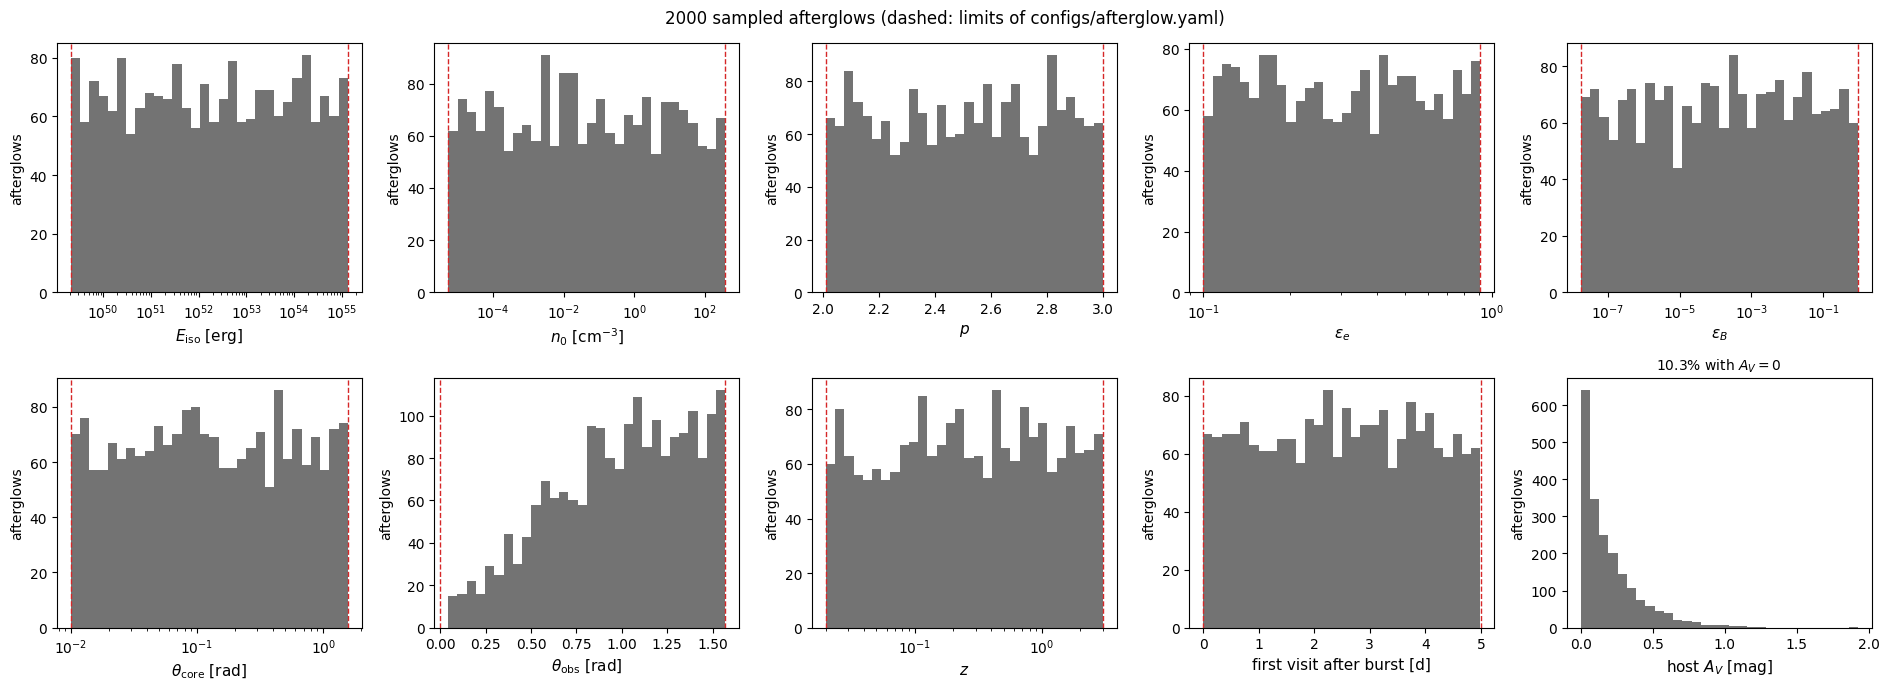

In [3]:
def sample_population(number_of_afterglows=NUMBER_OF_AFTERGLOWS, seed=POPULATION_SEED, plot=True):
    population = afterglow_contaminants.sample_afterglow_parameters(
        number_of_afterglows, np.random.default_rng(seed), CONFIG
    )
    population = population.set_index('afterglow_id', drop=False)
    if plot:
        plot_parameter_distributions(population)
    return population


population = sample_population(plot=True)

### 1.2 Curvas de luz de `afterglowpy`

Magnitud AB a 1.29 µm en función del tiempo desde el burst, para una muestra al azar. El color es el ángulo de visión en unidades del core: los on-axis decaen desde el principio, los off-axis suben primero.

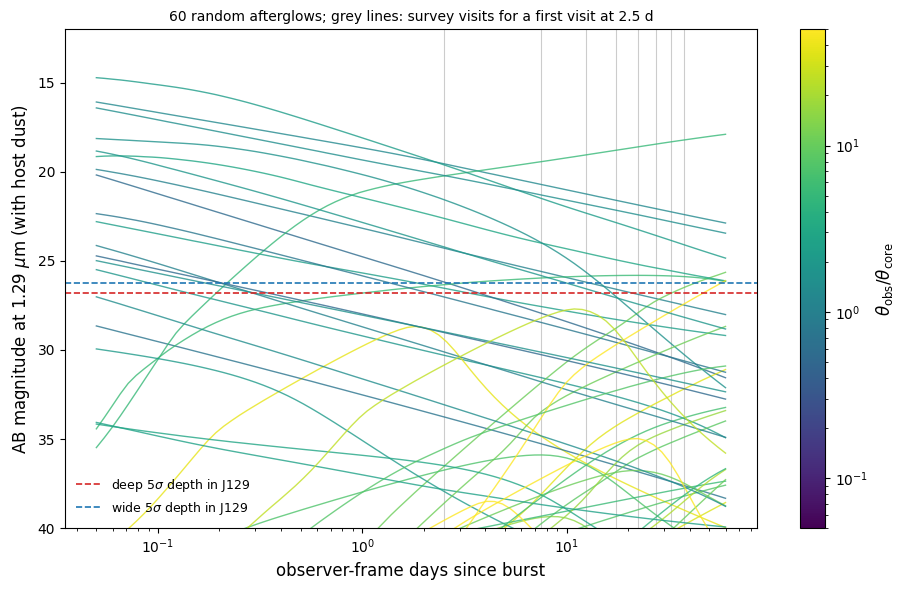

In [4]:
def afterglow_light_curves(population, number_shown=60, seed=1, plot=True):
    shown = population.sample(number_shown, random_state=seed)
    times_days = np.geomspace(0.05, 60.0, 80)
    wavelength = np.array([REFERENCE_WAVELENGTH_AA])
    magnitudes = np.full((number_shown, len(times_days)), np.nan)
    for row_index, (_, parameters) in enumerate(shown.iterrows()):
        flux_lambda = afterglow_contaminants.afterglow_spectra(parameters, times_days, wavelength)
        if flux_lambda is not None:
            magnitudes[row_index] = ab_magnitude_from_flux_lambda(wavelength, flux_lambda)[:, 0]
    if plot:
        plot_afterglow_light_curves(times_days, magnitudes, shown)
    return shown, times_days, magnitudes


light_curve_sample, light_curve_times, light_curve_magnitudes = afterglow_light_curves(population, plot=True)

### 1.3 Espectro con y sin polvo del host

Los seis afterglows con más $A_V$ de la población, en su primera visita. El polvo SMC se aplica en reposo, así que a igual $A_V$ enrojece más cuanto mayor es $z$.

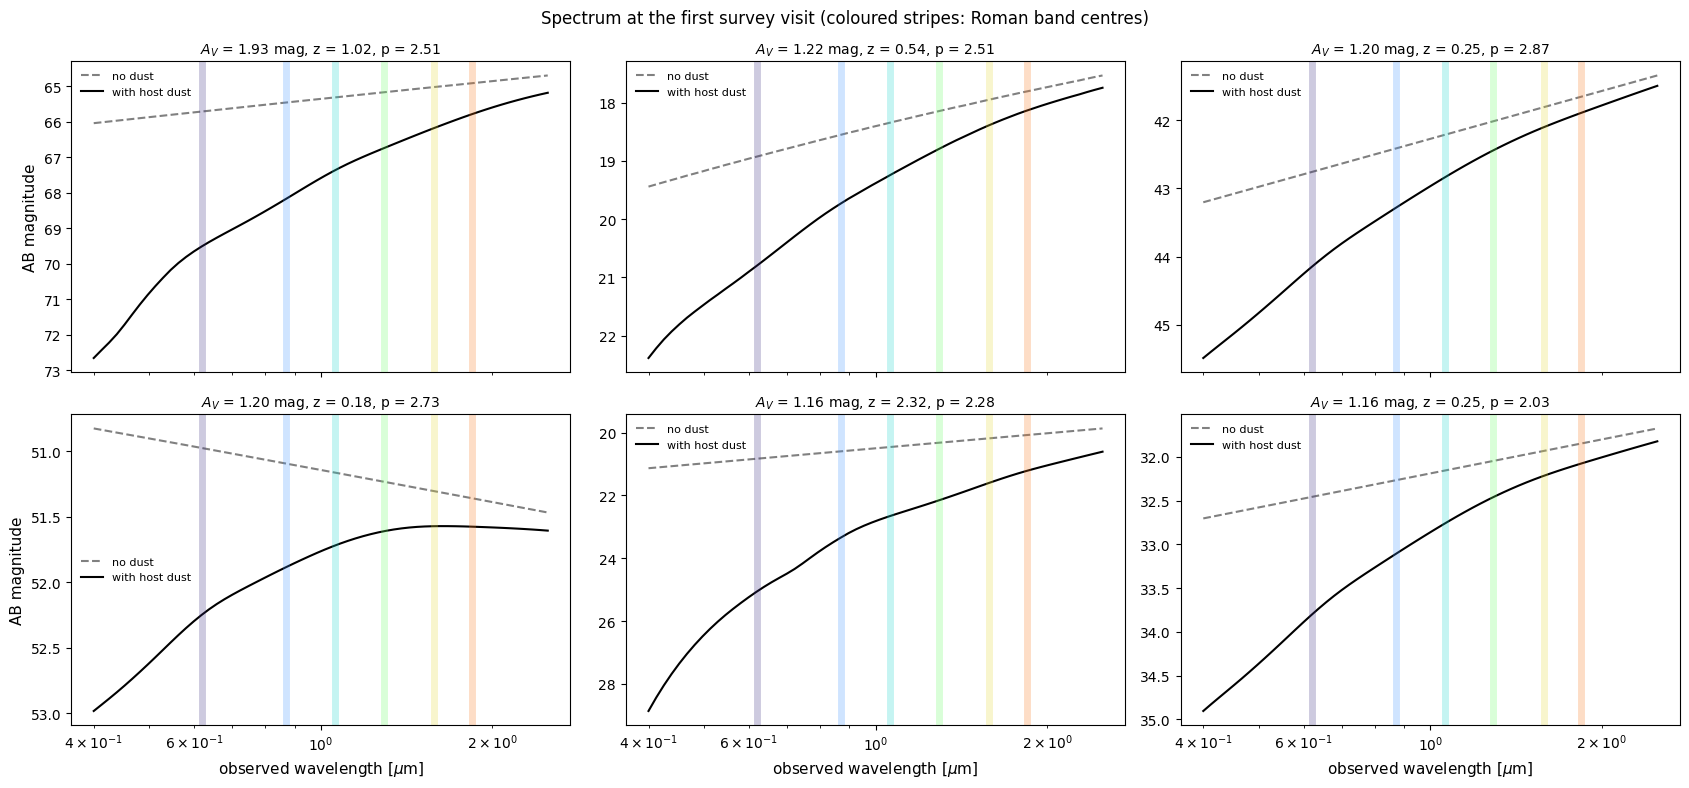

In [5]:
def dusty_afterglow_spectra(population, number_shown=6, plot=True):
    shown = population.sort_values('host_extinction_av', ascending=False).head(number_shown)
    spectra = []
    for _, parameters in shown.iterrows():
        first_visit = parameters['first_visit_time_days']
        dusty = afterglow_contaminants.afterglow_spectra(parameters, first_visit)[0]
        clean = afterglow_contaminants.afterglow_spectra(parameters, first_visit, with_host_dust=False)[0]
        spectra.append((dusty, clean))
    if plot:
        plot_afterglow_spectra(spectra, shown)
    return shown, spectra


dusty_sample, dusty_spectra = dusty_afterglow_spectra(population, plot=True)

## Parte 2 — Los afterglows en Roman

### 2.1 Magnitudes verdaderas en las visitas del survey

Cada afterglow se evalúa en sus 8 visitas (primera visita + cadencia de 5 d) y se pliega por los bandpasses de `galsim.roman`. La celda mide el tiempo por afterglow, que es lo que fija el costo de la generación completa.

2000 afterglows evaluated in 132 s wall time, 0 failed in afterglowpy: []


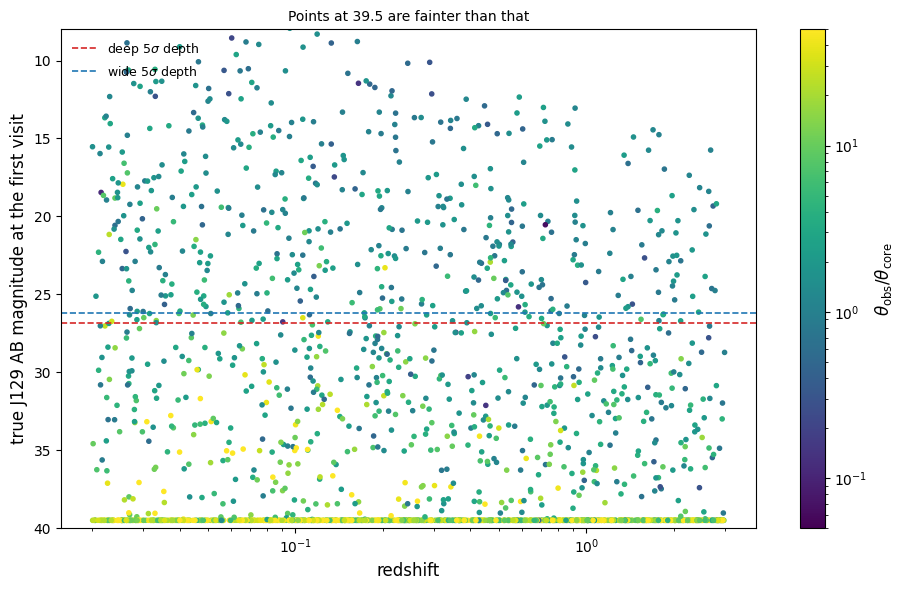

In [6]:
def roman_magnitudes_of_population(population, plot=True):
    tasks = []
    for _, parameters in population.iterrows():
        tasks.append(parameters.to_dict())
    start = time.perf_counter()
    with Pool() as pool:
        results = pool.map(afterglow_contaminants.evaluate_afterglow, tasks, chunksize=8)
    elapsed = time.perf_counter() - start
    magnitudes = {}
    failed = []
    for afterglow_id, afterglow_magnitudes in results:
        if afterglow_magnitudes is None:
            failed.append(afterglow_id)
        else:
            magnitudes[afterglow_id] = afterglow_magnitudes
    print(f'{len(magnitudes)} afterglows evaluated in {elapsed:.0f} s wall time, {len(failed)} failed in afterglowpy: {failed}')
    if plot:
        evaluated = population.loc[list(magnitudes)]
        first_visit_magnitude = np.empty(len(evaluated))
        for row_index, afterglow_id in enumerate(evaluated.index):
            first_visit_magnitude[row_index] = magnitudes[afterglow_id][REFERENCE_BAND][0]
        plot_roman_magnitudes(evaluated, first_visit_magnitude)
    return magnitudes


roman_magnitudes = roman_magnitudes_of_population(population, plot=True)

### 2.2 Ventanas con ruido y fracción detectada

Primero se descartan las configuraciones más brillantes que 15 mag en alguna visita y banda: están en el límite de saturación de Roman (extremo brillante de la tabla de NASA *Time to saturation for point source imaging*; ver `configs/afterglow.yaml`).

Después, el mismo `build_window_from_model` de las kilonovas: cadencia del tier, jitter del zeropoint, ruido en flujo y 4 épocas desde la primera detección S/N ≥ 5. Un afterglow sin ninguna visita detectada no deja ventana. La figura es la eficiencia de detección contra cada parámetro, calculada sobre los afterglows que pasan el corte de brillo: dice qué parte del espacio muestreado llega al training.

114 of 2000 afterglows discarded: brighter than 15 mag at some visit


deep: 445 windows from 1886 afterglows below the saturation limit


wide: 403 windows from 1886 afterglows below the saturation limit


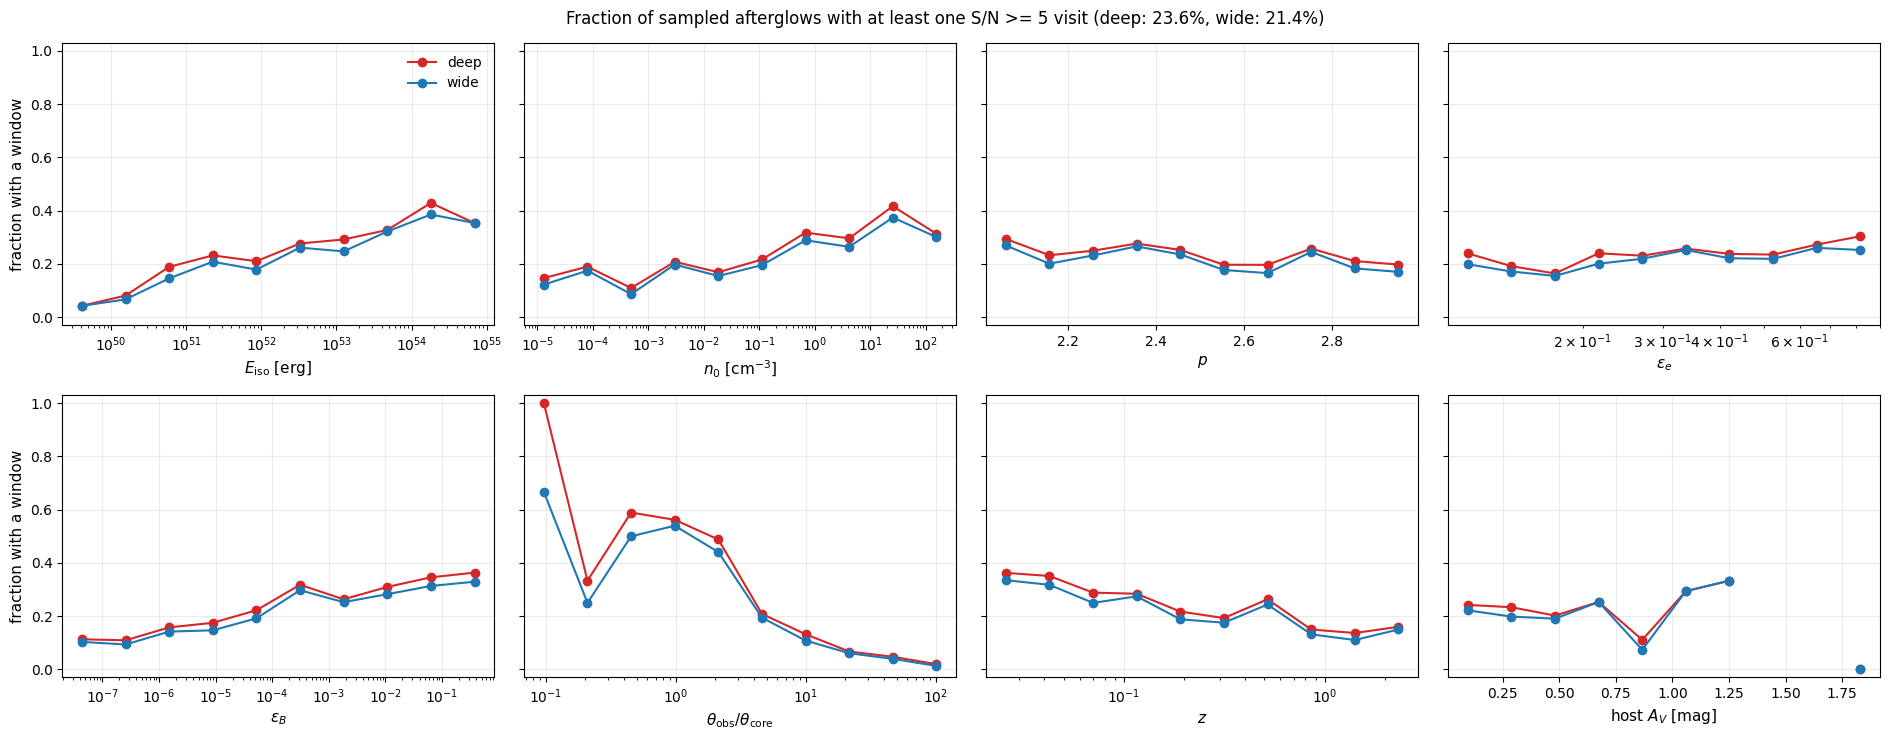

In [7]:
def build_population_windows(population, magnitudes, plot=True):
    kept_ids = []
    for afterglow_id in magnitudes:
        if not afterglow_contaminants.exceeds_bright_limit(magnitudes[afterglow_id], CONFIG):
            kept_ids.append(afterglow_id)
    bright_limit = float(CONFIG['saturation']['bright_limit_magnitude'])
    print(f'{len(magnitudes) - len(kept_ids)} of {len(magnitudes)} afterglows discarded: brighter than {bright_limit:g} mag at some visit')
    evaluated = population.loc[kept_ids]
    windows_by_tier = {}
    detected_by_tier = {}
    for tier in TIERS:
        tier_windows = []
        detected = np.zeros(len(evaluated), dtype=bool)
        for row_index, (afterglow_id, parameters) in enumerate(evaluated.iterrows()):
            window = afterglow_contaminants.build_afterglow_window(parameters, magnitudes[afterglow_id], TIER_CONSTANTS[tier])
            if window is not None:
                detected[row_index] = True
                tier_windows.append(window)
        windows_by_tier[tier] = pd.concat(tier_windows, ignore_index=True)
        detected_by_tier[tier] = detected
        print(f'{tier}: {detected.sum()} windows from {len(evaluated)} afterglows below the saturation limit')
    if plot:
        plot_detection_efficiency(evaluated, detected_by_tier)
    return windows_by_tier, detected_by_tier


windows_by_tier, detected_by_tier = build_population_windows(population, roman_magnitudes, plot=True)


### 2.3 Ejemplos de ventanas

Ocho ventanas al azar por tier, tal como las vería el clasificador.

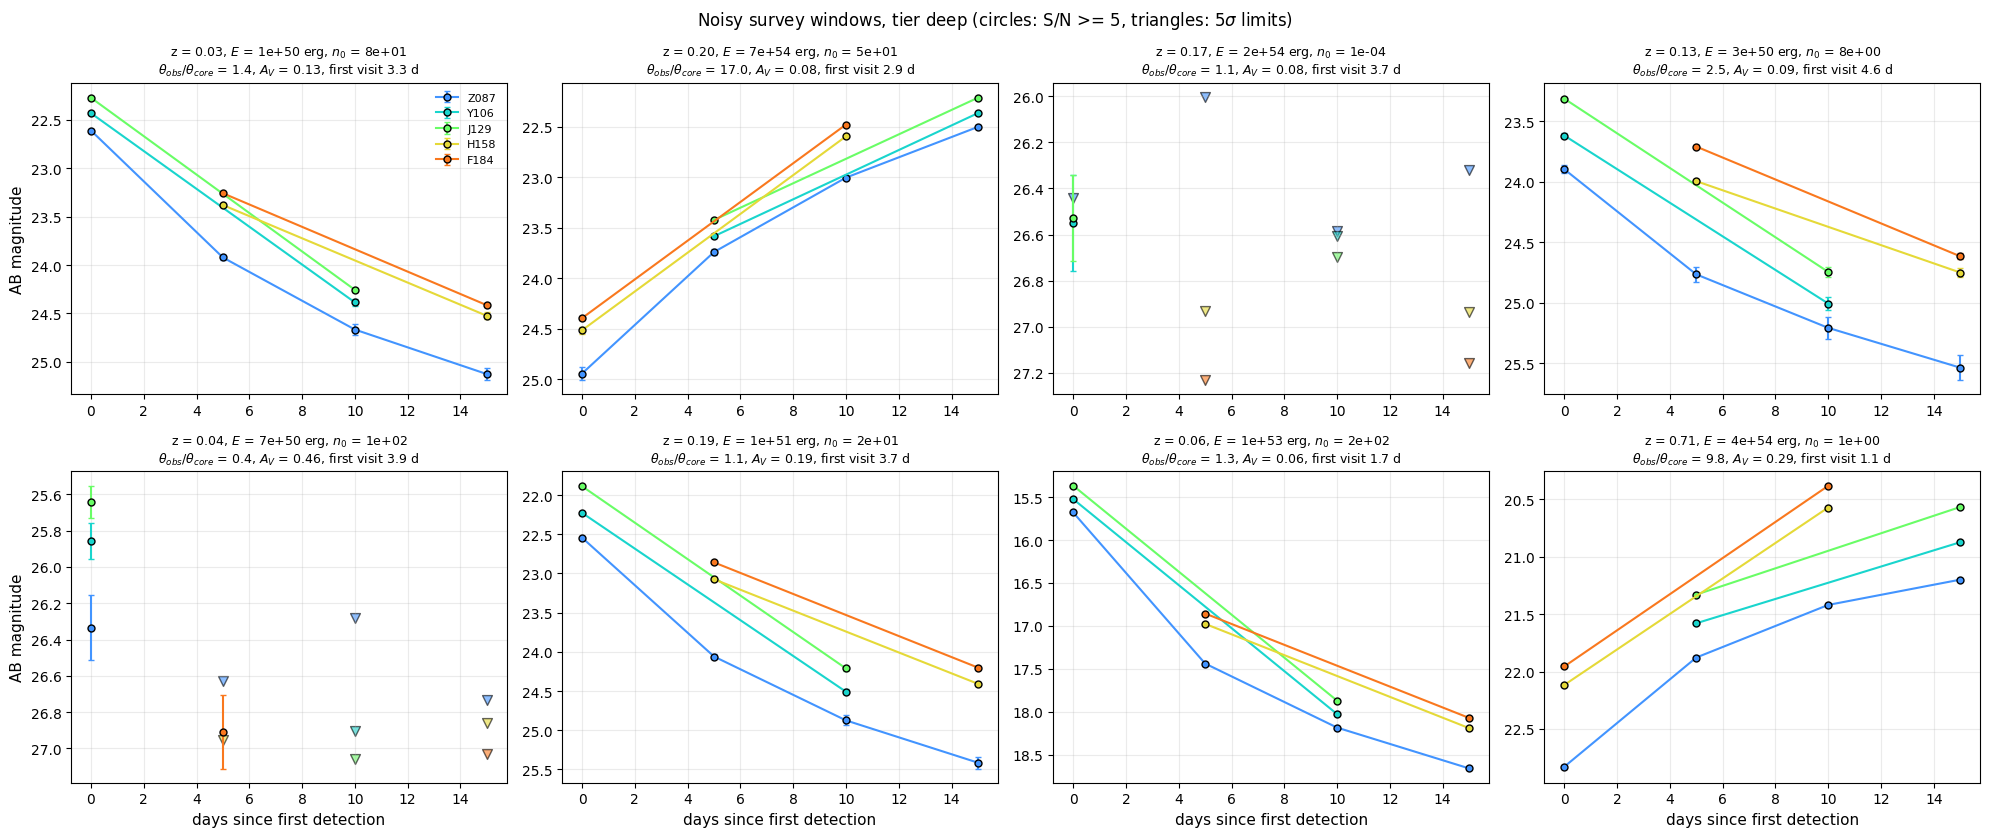

In [8]:
def example_windows(windows_by_tier, population, tier, number_shown=8, seed=0, plot=True):
    windows = windows_by_tier[tier]
    object_ids = np.random.default_rng(seed).choice(windows['object_id'].unique(), size=number_shown, replace=False)
    shown = windows[windows['object_id'].isin(object_ids)]
    if plot:
        plot_windows(shown, population, tier)
    return shown


deep_examples = example_windows(windows_by_tier, population, 'deep', plot=True)

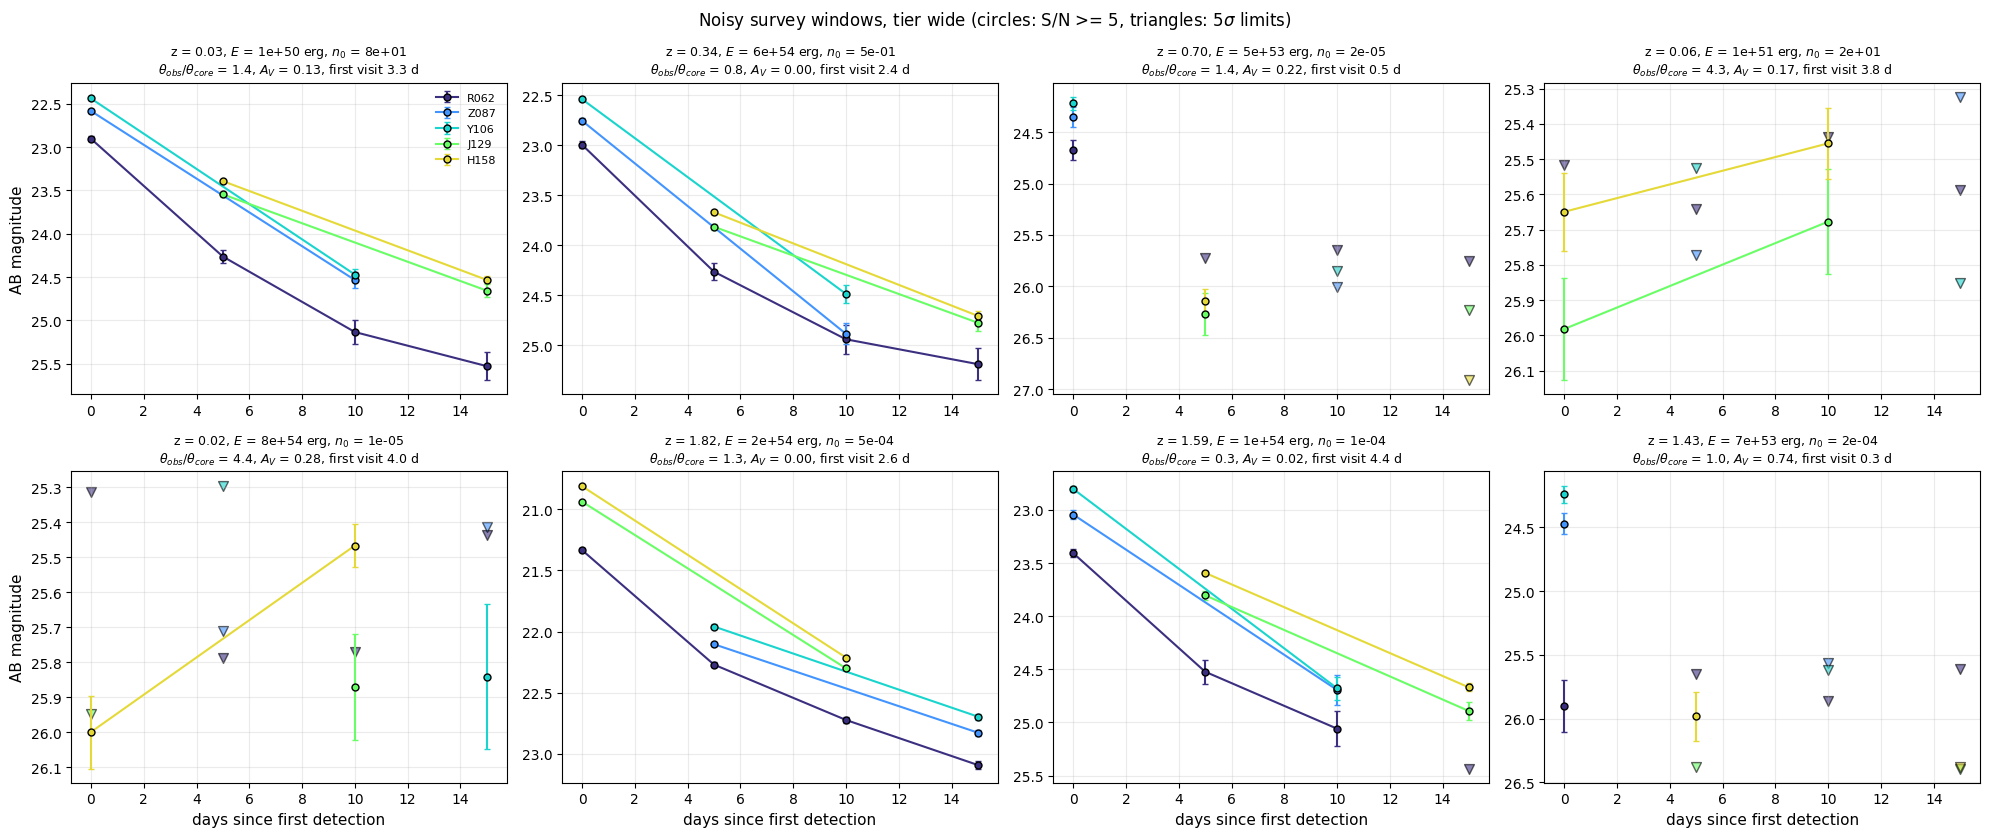

In [9]:
wide_examples = example_windows(windows_by_tier, population, 'wide', plot=True)

### 2.4 Los casos muy brillantes

Magnitud verdadera más brillante que alcanza cada afterglow en sus 8 visitas (cualquier banda) contra el redshift. El color es la energía isotrópica; los círculos son on-axis ($\theta_{\rm obs} < \theta_{\rm core}$) y los triángulos off-axis. La tabla lista los diez más brillantes.

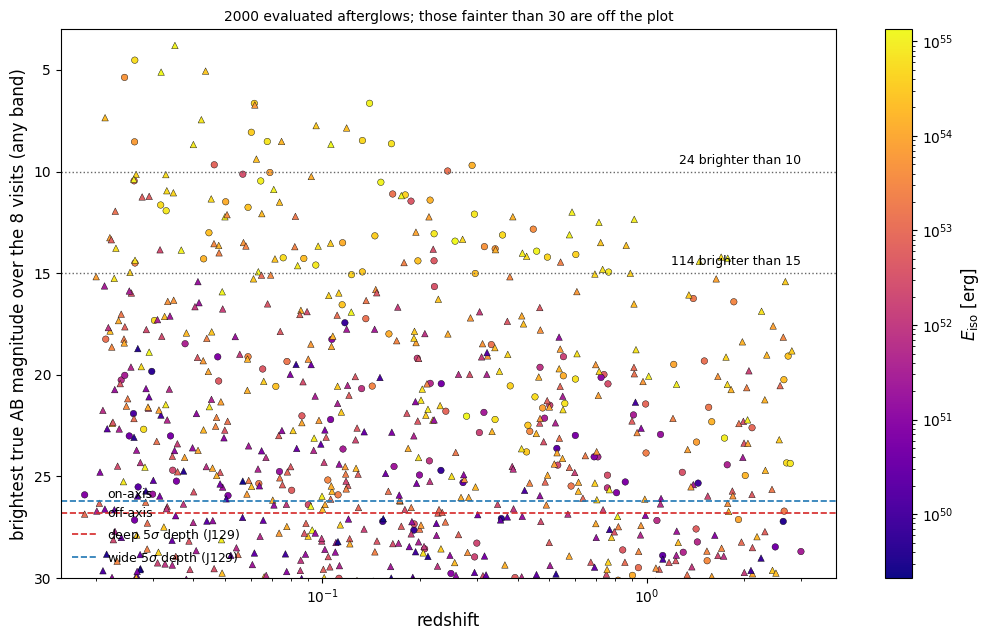

              brightest_magnitude  redshift  isotropic_energy_erg  density_cm3  epsilon_e  epsilon_b  core_angle_rad  viewing_angle_rad  first_visit_time_days
afterglow_id                                                                                                                                                  
1597                         3.79    0.0351               1.1e+55         1.28      0.351      0.372            0.36              0.527                 0.0607
456                          4.52    0.0264              5.78e+54         32.1      0.143   0.000185           0.739              0.244                  0.922
1311                         5.05    0.0436              2.83e+54         88.3      0.472    0.00013            0.53              0.626                  0.484
1454                          5.1    0.0318              1.29e+55          117      0.668      0.003            0.94               1.21                   3.41
1145                         5.37    0.0245   

In [10]:
BRIGHT_MAGNITUDE_THRESHOLDS = [15.0, 10.0]


def plot_brightest_magnitude(population, brightest_magnitude):
    on_axis = (viewing_over_core(population) < 1.0).to_numpy()
    energy = population['isotropic_energy_erg'].to_numpy()
    redshift = population['redshift'].to_numpy()
    norm = LogNorm(vmin=energy.min(), vmax=energy.max())
    figure, axis = plt.subplots(figsize=(10.5, 6.5))
    for selection, marker, label in [(on_axis, 'o', 'on-axis'), (~on_axis, '^', 'off-axis')]:
        scatter = axis.scatter(redshift[selection], brightest_magnitude[selection], c=energy[selection], norm=norm,
                               cmap='plasma', marker=marker, s=22, edgecolor='black', linewidth=0.3, label=label)
    for tier in TIERS:
        axis.axhline(limiting_magnitude(tier, REFERENCE_BAND), color=TIER_COLOR[tier], linestyle='--', linewidth=1.2,
                     label=f'{tier} 5$\\sigma$ depth ({REFERENCE_BAND})')
    for threshold in BRIGHT_MAGNITUDE_THRESHOLDS:
        count = int((brightest_magnitude < threshold).sum())
        axis.axhline(threshold, color='0.4', linestyle=':', linewidth=1)
        axis.text(redshift.max(), threshold - 0.25, f'{count} brighter than {threshold:g}', ha='right', va='bottom', fontsize=9)
    axis.set_xscale('log')
    axis.set_ylim(30, 3)
    axis.set_xlabel('redshift', fontsize=12)
    axis.set_ylabel('brightest true AB magnitude over the 8 visits (any band)', fontsize=12)
    figure.colorbar(scatter, ax=axis).set_label(r'$E_{\rm iso}$ [erg]', fontsize=12)
    axis.legend(frameon=False, fontsize=9, loc='lower left')
    axis.set_title(f'{len(population)} evaluated afterglows; those fainter than 30 are off the plot', fontsize=10)
    plt.tight_layout()
    plt.show()


def brightest_afterglows(population, magnitudes, number_listed=10, plot=True):
    evaluated = population.loc[list(magnitudes)]
    brightest_magnitude = np.empty(len(evaluated))
    for row_index, afterglow_id in enumerate(evaluated.index):
        band_minima = []
        for band in ALL_ROMAN_BANDS:
            band_minima.append(np.nanmin(magnitudes[afterglow_id][band]))
        brightest_magnitude[row_index] = min(band_minima)
    if plot:
        plot_brightest_magnitude(evaluated, brightest_magnitude)
    table = evaluated[['redshift', 'isotropic_energy_erg', 'density_cm3', 'epsilon_e', 'epsilon_b',
                       'core_angle_rad', 'viewing_angle_rad', 'first_visit_time_days']].copy()
    table.insert(0, 'brightest_magnitude', brightest_magnitude)
    return table.sort_values('brightest_magnitude').head(number_listed)


brightest_table = brightest_afterglows(population, roman_magnitudes, plot=True)
print(brightest_table.to_string(float_format=lambda value: f'{value:.3g}'))
